# Семинар 3. Проверяем число, оцениваем вероятность, выбираем действие

Работаем с **Auto MPG**: сначала прогнозируем экономичность автомобиля, затем вероятность
события «экономичность ниже 20 mpg». Это две задачи на одних измерениях, не две метрики одной задачи.

Распакуйте **весь комплект**, откройте этот notebook в Jupyter. Данные лежат локально:
`auto_mpg_train.csv`, `auto_mpg_valid.csv`, `auto_mpg_test.csv`. Загрузка из сети на занятии не нужна.

In [1]:
import math
import sys
from pathlib import Path

# Готовый поиск корня комплекта; не упражнение по Python.
HERE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
ROOT = next(
    (
        p
        for p in [HERE, *HERE.parents]
        if (
            p / "materials/03-probability-and-decisions/code/seminar3_support.py"
        ).is_file()
        or (
            (p / "seminar3_support.py").is_file()
            and (p / "data/auto_mpg_train.csv").is_file()
        )
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Откройте notebook в репозитории или распакуйте весь архив семинара."
    )
CODE_DIR = (
    ROOT / "materials/03-probability-and-decisions/code"
    if (ROOT / "materials/03-probability-and-decisions/code").is_dir()
    else ROOT
)
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from collections.abc import Sequence

import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display
from numpy.typing import NDArray
from sklearn.base import BaseEstimator
from sklearn.pipeline import Pipeline

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
from seminar3_support import (
    C_FN,
    C_FP,
    CUTOFF_MPG,
    DATA_DIR,
    FEATURES,
    classification_context,
    comparison_table,
    decision_report,
    final_report,
    load_part,
    make_classifier,
    make_regressor,
    plot_budget,
    plot_costs,
    plot_data,
    threshold_table,
    try_task,
)
from sklearn.model_selection import KFold, cross_val_score
from threadpoolctl import threadpool_limits

checks = {}
frozen_regression = None
chosen_tau = None
theoretical_tau = None
OPEN_TEST = False

## B00. Данные и две содержательные задачи

**Задача.** Для описанного автомобиля, до измерения его экономичности в городском цикле,
спрогнозировать `mpg` — число миль на галлон. **Больше mpg — экономичнее.**

Одна строка — наблюдение об автомобиле определённой модели и года. В полном источнике 398 строк.
В нашем эксперименте 238 строк train, 80 validation и 80 test; разбиение дано готовым.

| Поле | Смысл | Роль здесь |
|---|---|---|
| `weight` | Масса, фунты | Признак |
| `horsepower` | Мощность; встречаются пропуски | Признак |
| `model_year` | Код модельного года, 70–82 | Признак |
| `mpg` | Экономичность в городском цикле | Ответ регрессии |
| `name`, `row_id` | Название и идентификатор строки | Не признаки |

Считаем, что три выбранных признака известны в момент прогноза. Другие столбцы оставлены
для чтения таблицы, но не подаются моделям.

,name,weight,horsepower,model_year,mpg
0,plymouth valiant,3121,105.0,73,18.0
1,amc matador,3632,110.0,74,16.0
2,datsun 210,2020,65.0,79,31.8
3,volkswagen dasher,2190,78.0,77,30.5
4,chevrolet monte carlo landau,3425,145.0,78,19.2
5,saab 99e,2375,95.0,70,25.0


weight        0
horsepower    3
model_year    0
Name: Пропуски в train, dtype: int64

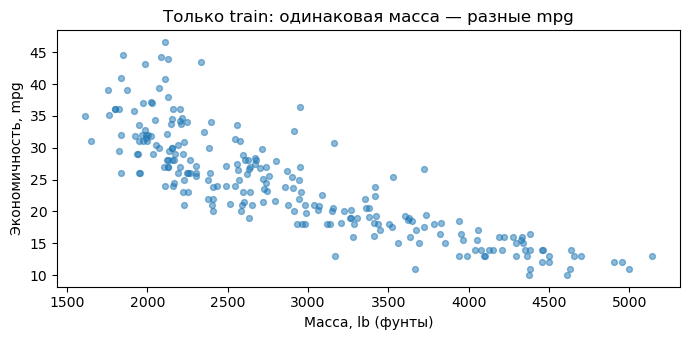

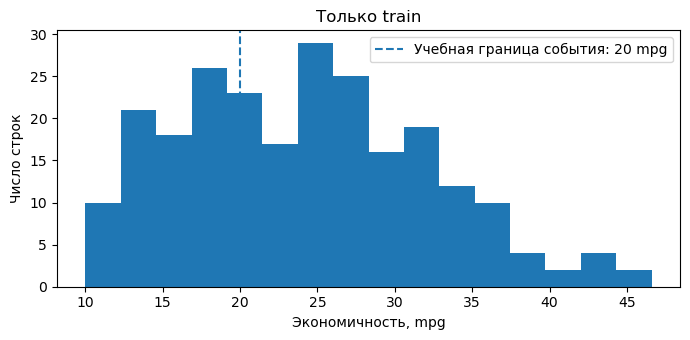

In [2]:
train = load_part("train")  # Validation и test здесь не читаем.
display(train[["name", *FEATURES, "mpg"]].head(6))
display(train[FEATURES].isna().sum().rename("Пропуски в train"))
plot_data(train)

## B01. Что означает одна строка CV-отчёта

### Вспоминаем лекцию 4

$f$ — уже обученный предсказатель; $y_i$ — наблюдённый ответ; $m$ — размер проверки.
Эмпирический риск — средняя потеря на конкретной таблице:

$$\widehat R_S(f)=\frac1m\sum_{i=1}^m\ell(y_i,f(x_i)).$$

Сегодня в отчёте выбираем $\ell(y,\widehat y)=|y-\widehat y|$, поэтому считаем **MAE в mpg**.
Обучение линейной регрессии по квадратам и отчёт по MAE не противоречат друг другу.

Пример **трёх** фолдов только внутри train; A, B, C — непересекающиеся группы строк:

| Запуск | Fit всего pipeline | Проверка |
|---|---|---|
| 1 | B + C | A |
| 2 | A + C | B |
| 3 | A + B | C |

Каждый запуск начинает с необученного pipeline: медиана пропусков, масштабы, коэффициенты.
В отчёте — среднее ошибок фолдов. Это не ансамбль трёх моделей.

**Наш протокол:** train — EDA, CV регрессии и обучение классификатора;
validation — выбор порога классификатора; test — одна заключительная проверка **обоих** зафиксированных решений.
Поле `test_score` в CV означает проверочный fold, а не наш отдельный файл test.

## B02. Простые регрессии на одинаковых фолдах

Заранее фиксируем четыре решения: медиана train; прямая по массе; линейная модель по трём
признакам; Ridge по тем же трём признакам с фиксированным `alpha=30`.
Медианная константа соответствует нашей отчётной MAE. Модели учатся по своим квадратным критериям.

**Самостоятельно, 3–4 строки.** В `mean_cv_mae(model, X, y)` создайте
`KFold(n_splits=4, shuffle=True, random_state=17)`, вызовите `cross_val_score`
с `scoring="neg_mean_absolute_error"`, верните положительную среднюю MAE.

`model` уже содержит всю предобработку. Вам не нужны индексы фолдов, клонирование модели или NumPy-матрицы.
Общий вид вызова: `cross_val_score(model, X, y, cv=..., scoring=..., n_jobs=1)`.
Минус в имени scorer нужен scikit-learn соглашению «больше score — лучше».

In [3]:
def mean_cv_mae(model: BaseEstimator, X: pd.DataFrame, y: pd.Series) -> float:
    """Средняя положительная MAE в mpg по четырём фолдам внутри train.

    model — необученный estimator с предобработкой; X — таблица (n, p),
    y — ответы mpg длины n в том же порядке. Исходный model не обучается."""
    cv = KFold(n_splits=4, shuffle=True, random_state=17)
    scores = cross_val_score(
        model, X, y, cv=cv, scoring="neg_mean_absolute_error", n_jobs=1
    )
    return float(-scores.mean())

In [4]:
def check_B02():
    tr = load_part("train")
    with threadpool_limits(limits=1):
        result = mean_cv_mae(make_regressor("linear"), tr[FEATURES], tr.mpg)
        reference = comparison_table()["linear"].mean()
    assert math.isclose(result, reference, rel_tol=1e-10)
    assert result > 0
    return result


checks["B02"] = try_task(check_B02)
if checks["B02"] is not None:
    print("MAE собственного вызова:", checks["B02"])

MAE собственного вызова: 2.6631771732940175


In [5]:
# Отдельный готовый библиотечный эксперимент, не результат незаполненной функции.
reference_folds = comparison_table(k=4, seed=17)
display(reference_folds.rename_axis("Проверочный fold"))
reference_means = reference_folds.mean().rename("Средняя CV MAE, mpg")
display(reference_means)
frozen_regression = str(reference_means.idxmin())
print(
    "Выбор в этой демонстрации по заранее заданному правилу min CV MAE:",
    frozen_regression,
)

,baseline,weight,linear,ridge
Проверочный fold,,,,
0,6.890000,3.759560,2.998052,3.074962
1,6.791667,2.962214,2.297355,2.460989
2,6.701695,2.749683,2.665892,2.754487
3,6.344068,3.515173,2.691410,2.717164


baseline    6.681857
weight      3.246658
linear      2.663177
ridge       2.751901
Name: Средняя CV MAE, mpg, dtype: float64

Выбор в этой демонстрации по заранее заданному правилу min CV MAE: linear


## B04D. Сколько фолдов стоит оплачивать: короткая демонстрация

Одна фиксированная линейная модель; меняем **только протокол её оценки**.

При увеличении K в train каждого fit остаётся больше строк: в идеализированном равномерном
разбиении доля равна $1-1/K$. Для 3 и 4 это $2/3$ и $3/4$.
Ниже реальный опыт в референсном окружении.

,K,mae,seconds,cumulative_fits
0,3,2.648445,0.022629,3
1,4,2.663177,0.037312,7
2,5,2.630828,0.036042,12
3,8,2.671218,0.060513,20
4,13,2.653936,0.087819,33
5,21,2.643739,0.128810,54
6,34,2.655140,0.233201,88
7,55,2.630286,0.326117,143
8,88,2.661537,0.575317,231
9,141,2.647589,0.917355,372


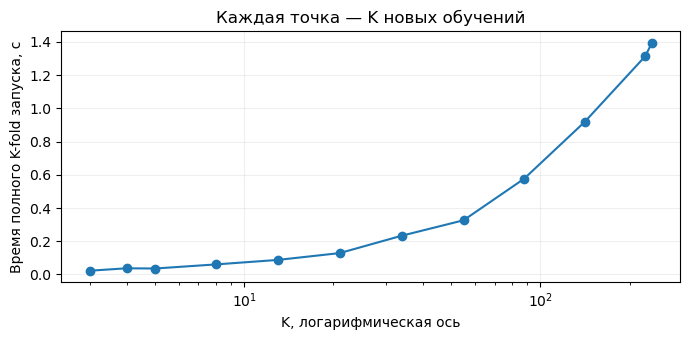

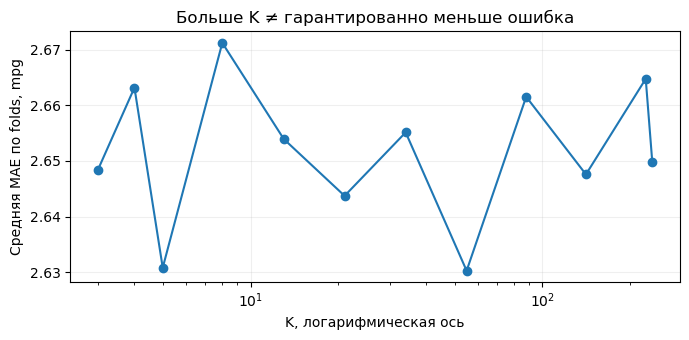

In [6]:
k_reference = pd.read_csv(DATA_DIR / "cv_k_reference.csv")
display(k_reference[["K", "mae", "seconds", "cumulative_fits"]])
plot_budget(k_reference)

## B06. Из численного ответа — событие

### Вспоминаем мостик из лекции 5

Пусть T — экономичность в mpg. Определим новое наблюдаемое событие:

$$Y=\mathbf1[T<20].$$

Теперь хотим $\pi_\theta(x)$ — оценку вероятности $Y=1$, а не среднего значения T.
Число 20 выбрано заранее **для учебной задачи**.

**Самостоятельно:** преобразуйте список mpg в список меток. Строгое неравенство важно:
20 mpg относится к классу 0. Достаточно цикла или спискового выражения.


In [7]:
def event_labels(values: Sequence[float]) -> list[int]:
    """Значения mpg длины n → список из n меток 0/1; событие строго mpg < 20."""
    return [1 if v < 20 else 0 for v in values]

In [8]:
def check_B06():
    assert event_labels([19.9, 20, 21]) == [1, 0, 0]
    labels = event_labels(list(load_part("train").mpg))
    return sum(labels) / len(labels)


checks["B06"] = try_task(check_B06)
if checks["B06"] is not None:
    print("Доля класса 1 на train:", checks["B06"])

Доля класса 1 на train: 0.3319327731092437


При построении X нельзя оставить ни `mpg`, ни `1/mpg`, ни уже вычисленный класс.
Мы продолжаем пользоваться только массой, мощностью и модельным годом.
**20 mpg и τ=0.5 — разные величины в разных единицах.**

## B07. Вероятности одной обученной LogReg

### Теория, которую используем сейчас

$x$ — исходные признаки; $z=\varphi(x)$ — признаки после заполнения пропусков и масштабирования.
$b,w$ — обучаемые коэффициенты. Цепочка из лекции 5:

$$a=b+w^\top z,\qquad \pi_\theta(x)=\sigma(a)=\frac1{1+e^{-a}},
\qquad \widehat y_\tau=\mathbf1[\pi_\theta(x)\ge\tau].$$

LogReg обучается по log loss с регуляризацией, а не по числу ошибок после порога.
Используем **готовый** solver и фиксированное C=1. Предобработка — внутри pipeline.

**Самостоятельно:** `fit_probabilities(model, X_train, y_train, X_valid)` должна обучить
model на train, найти столбец класса 1 через `list(model.classes_).index(1)` и вернуть
его `predict_proba` на validation. Объяснение `[:, positive]` уже дано: все строки, один столбец.

In [9]:
def fit_probabilities(
    model: Pipeline, X_train: pd.DataFrame, y_train: pd.Series, X_valid: pd.DataFrame
) -> NDArray[np.float64]:
    """Обучить model на train и вернуть P(Y=1) для validation, массив (n_valid,).

    X_train и X_valid содержат одинаковые признаки; y_train — метки 0/1
    длины n_train. Функция изменяет model через fit; validation не участвует в fit."""
    model.fit(X_train, y_train)
    positive = list(model.classes_).index(1)
    return model.predict_proba(X_valid)[:, positive]

In [10]:
def check_B07():
    tr, va = load_part("train"), load_part("valid")
    student_model = make_classifier()
    values = fit_probabilities(
        student_model, tr[FEATURES], (tr.mpg < CUTOFF_MPG).astype(int), va[FEATURES]
    )
    _, reference, _ = classification_context()
    np.testing.assert_allclose(values, reference, atol=1e-8)
    return values


checks["B07"] = try_task(check_B07)
if checks["B07"] is not None:
    print("Первые пять вероятностей:", checks["B07"][:5])

# Независимый готовый референс для следующих блоков. Не подмена student_model.
reference_classifier, pi_valid, y_valid_class = classification_context()
print("Далее фиксированный библиотечный референс; valid-строк:", len(pi_valid))

Первые пять вероятностей: [0.99698842 0.01107976 0.05756671 0.39307003 0.03233352]
Далее фиксированный библиотечный референс; valid-строк: 80


**Проверка понимания:** при изменении τ с 0.5 на 0.2 что нужно переобучить?

## B08. Ошибки как действия и их цена

Для каждого объекта есть факт y и вероятность $\pi$. Действие:
$\widehat y=\mathbf1[\pi\ge\tau]$. Ложное предупреждение (FP) стоит 1 условную единицу,
пропуск события (FN) — 4. Верные решения бесплатны.

$$\text{Cost}=C_{FP}\,FP+C_{FN}\,FN=FP+4FN.$$

| Факт / действие | 0 | 1 |
|---|---|---|
| 0 | TN | FP |
| 1 | FN | TP |

**Сначала вручную:** в таблице ниже при τ=0.5 найдите один FP и один FN.
Затем замените τ на 0.2, не меняя вероятности.

In [11]:
small_y = [1, 0, 1, 0, 1, 0]
small_pi = [0.85, 0.75, 0.55, 0.35, 0.25, 0.05]
display(pd.DataFrame({"y": small_y, "pi": small_pi}))

,y,pi
0,1,0.85
1,0,0.75
2,1,0.55
3,0,0.35
4,1,0.25
5,0,0.05


In [12]:
def decisions(
    probabilities: Sequence[float] | NDArray[np.float64], tau: float
) -> list[int]:
    """Вероятности длины n из [0, 1] и порог tau → n меток; равенство даёт 1."""
    return [1 if p >= tau else 0 for p in probabilities]

In [13]:
def check_B08_decisions():
    assert decisions([0.2, 0.5, 0.8], 0.5) == [0, 1, 1]
    assert decisions([0, 1], 0.2) == [0, 1]
    return True


checks["B08_decisions"] = try_task(check_B08_decisions)

In [14]:
def error_cost(
    y_true: Sequence[int], y_pred: Sequence[int], c_fp: float = 1, c_fn: float = 4
) -> float:
    """Суммарная цена ошибок в условных единицах, без деления на число строк.

    y_true и y_pred — согласованные по порядку списки меток 0/1 одинаковой
    длины; c_fp и c_fn — положительные цены FP и FN. Верные действия бесплатны."""
    total = 0
    for yt, yp in zip(y_true, y_pred):
        if yt == 0 and yp == 1:
            total += c_fp
        elif yt == 1 and yp == 0:
            total += c_fn
    return total

In [15]:
def check_B08_cost():
    assert error_cost([0, 1, 1], [1, 0, 1]) == 5
    assert error_cost([0, 1], [0, 1]) == 0
    assert error_cost([0, 1], [1, 0], c_fp=2, c_fn=7) == 9
    return True


checks["B08_cost"] = try_task(check_B08_cost)
if checks["B08_decisions"] and checks["B08_cost"]:
    for tau in [0.5, 0.2, 0.8]:
        labels = decisions(small_pi, tau)
        print("tau =", tau, "метки:", labels, "цена:", error_cost(small_y, labels))
        display(pd.Series(decision_report(small_y, labels)))

tau = 0.5 метки: [1, 1, 1, 0, 0, 0] цена: 5


TN           2.000000
FP           1.000000
FN           1.000000
TP           2.000000
accuracy     0.666667
precision    0.666667
recall       0.666667
cost         5.000000
dtype: float64

tau = 0.2 метки: [1, 1, 1, 1, 1, 0] цена: 2


TN           1.000000
FP           2.000000
FN           0.000000
TP           3.000000
accuracy     0.666667
precision    0.600000
recall       1.000000
cost         2.000000
dtype: float64

tau = 0.8 метки: [1, 0, 0, 0, 0, 0] цена: 8


TN           3.000000
FP           0.000000
FN           2.000000
TP           1.000000
accuracy     0.666667
precision    1.000000
recall       0.333333
cost         8.000000
dtype: float64

- $\mathrm{Precision}=TP/(TP+FP)$ — доля верных среди предупреждений;
- $\mathrm{Recall}=TP/(TP+FN)$ — доля найденных событий.

При нуле предупреждений precision не определена; код показывает NaN. При отсутствии событий так же
не определена recall.

## B09. Главная формула: вывести порог из цены ошибок

### Зачем нужна математика

Число 0.5 не учитывает цену ошибки. Хотим выбрать действие с меньшим ожидаемым ущербом.

$x$ фиксирован; $q=P(Y=1\mid x)$ — **истинная** вероятность события.
$u\in\{0,1\}$ — действие; $\mathcal R(u\mid x)$ — его условный ожидаемый ущерб.
$C_{FP}>0$, $C_{FN}>0$ — постоянные цены; верные действия бесплатны, ограничения на число
предупреждений нет. В модели используем лишь оценку $\pi_\theta(x)$ неизвестного q.

На лекции уже было:

$$\mathcal R(1\mid x)=C_{FP}(1-q),\qquad
\mathcal R(0\mid x)=C_{FN}q.$$

**Самостоятельно:** решите неравенство
$C_{FP}(1-q)\le C_{FN}q$ относительно q. Что произойдёт с порогом, если пропуск станет дороже?
Затем перенесите формулу в `bayes_threshold`: одна строка.

In [16]:
def bayes_threshold(c_fp: float, c_fn: float) -> float:
    """Положительные цены FP и FN → теоретический порог вероятности из (0, 1)."""
    return c_fp / (c_fp + c_fn)

In [17]:
def check_B09():
    assert math.isclose(bayes_threshold(1, 4), 0.2)
    assert math.isclose(bayes_threshold(3, 3), 0.5)
    assert math.isclose(bayes_threshold(10, 40), 0.2)
    assert bayes_threshold(1, 9) < bayes_threshold(1, 4)
    return bayes_threshold(C_FP, C_FN)


checks["B09"] = try_task(check_B09)
if checks["B09"] is not None:
    theoretical_tau = checks["B09"]
    print("Теоретический порог:", theoretical_tau)

Теоретический порог: 0.2


## B10. Порог по validation, а не по test

На практике q неизвестно. Другой способ — сравнить действия по сохранённым вероятностям validation.
Модель уже обучена; кандидаты τ = 0.1, 0.2, …, 0.9 и цена FP+4FN объявлены заранее.

**Самостоятельно:** `select_threshold(rows)` получает обычный список словарей с ключами
`tau` и `cost`, упорядоченный по τ. Верните τ первой строки с минимальной ценой.
Достаточно `min(rows, key=...)`; при равенстве остаётся первая строка.

После выбора фиксируем и регрессионную модель, и классификатор, и τ.
Test до этого не открываем ни для одной из задач: они используют связанные ответы на одних строках.

,tau,TN,FP,FN,TP,accuracy,precision,recall,cost
0,0.1,33,10,1,36,0.8625,0.782609,0.972973,14.0
1,0.2,37,6,2,35,0.9000,0.853659,0.945946,14.0
2,0.3,39,4,2,35,0.9250,0.897436,0.945946,12.0
3,0.4,40,3,7,30,0.8750,0.909091,0.810811,31.0
4,0.5,40,3,10,27,0.8375,0.900000,0.729730,43.0
5,0.6,42,1,11,26,0.8500,0.962963,0.702703,45.0
6,0.7,42,1,12,25,0.8375,0.961538,0.675676,49.0
7,0.8,42,1,13,24,0.8250,0.960000,0.648649,53.0
8,0.9,42,1,14,23,0.8125,0.958333,0.621622,57.0


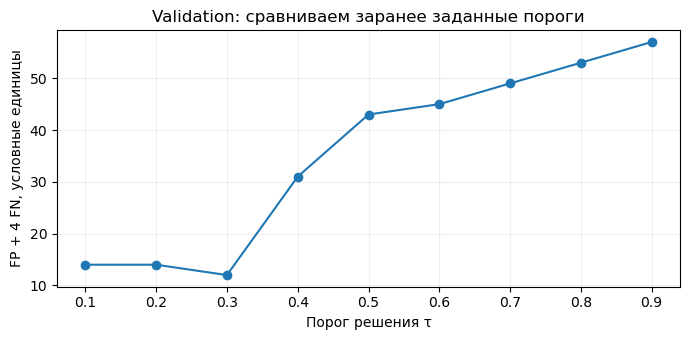

In [18]:
_, pi_valid, y_valid_class = classification_context()
validation_table = threshold_table(y_valid_class, pi_valid)
display(validation_table)
plot_costs(validation_table)

In [19]:
def select_threshold(rows: list[dict[str, float]]) -> float:
    """Непустой список строк с tau и cost → tau первой строки с минимальной cost.

    Строки упорядочены по tau; при равенстве цен сохраняется первая строка.
    Дополнительные ключи отчёта не используются."""
    best = min(rows, key=lambda row: row["cost"])
    return float(best["tau"])

In [20]:
def check_B10():
    assert select_threshold([{"tau": 0.2, "cost": 3}, {"tau": 0.4, "cost": 3}]) == 0.2
    assert select_threshold([{"tau": 0.2, "cost": 5}, {"tau": 0.4, "cost": 3}]) == 0.4
    return float(select_threshold(validation_table.to_dict("records")))


checks["B10"] = try_task(check_B10)
if checks["B10"] is not None:
    chosen_tau = checks["B10"]
    print("Выбрано по validation; модель не переобучаем:", chosen_tau)

Выбрано по validation; модель не переобучаем: 0.3


## B15. Финальная проверка

**До открытия test** запишите: какая регрессионная модель выбрана по CV, какой классификатор обучен,
по какому правилу взят τ. После открытия не менять ни представление, ни модель, ни τ.

В итоговой демонстрации используем один фиксированный библиотечный pipeline классификатора.
Он **не переобучается** после выбора τ.

Когда оба решения зафиксированы, поменяйте `OPEN_TEST` на True.

In [21]:
OPEN_TEST = True  # Только после фиксации обоих решений.

In [22]:
fixed_tau = chosen_tau  # Маршрут A: порог зафиксирован по validation в B10.
if OPEN_TEST:
    if frozen_regression is None or fixed_tau is None:
        raise RuntimeError(
            "Сначала завершите выбор регрессии и порога. Test не открыт."
        )
    final = final_report(tau=fixed_tau, regression_kind=frozen_regression)
    print(
        "Регрессия MAE / baseline, mpg:", final["regression_mae"], final["baseline_mae"]
    )
    display(final["policies"])
    print(
        "Одинаковые вероятности при разных tau: log loss =",
        final["log_loss"],
        "; ROC-AUC =",
        final["roc_auc"],
    )
else:
    print("Test не открыт: OPEN_TEST=False")
print(
    "Самостоятельные части:",
    {name: value is not None for name, value in checks.items()},
)

Регрессия MAE / baseline, mpg: 2.765005937488037 6.644999999999999


,policy,TN,FP,FN,TP,accuracy,precision,recall,cost
0,Всегда 0,45,0,35,0,0.5625,NaN,0.000000,140.0
1,Всегда 1,0,45,0,35,0.4375,0.437500,1.000000,45.0
2,LogReg: τ=0.5,42,3,8,27,0.8625,0.900000,0.771429,35.0
3,LogReg: фиксированный τ,38,7,6,29,0.8375,0.805556,0.828571,31.0


Одинаковые вероятности при разных tau: log loss = 0.29450890278300845 ; ROC-AUC = 0.9511111111111111
Самостоятельные части: {'B02': True, 'B06': True, 'B07': True, 'B08_decisions': True, 'B08_cost': True, 'B09': True, 'B10': True}


**Самопроверка.** Если дать вдвое больше времени на K-fold,
обучить ту же модель на том же train и затем изменить порог, какие из следующих величин
обязаны измениться:
- веса
- качество оценки по CV
- вероятности
- метки
- цена ошибок?

На выбор — дополнить: почему нельзя подбирать τ по test, даже если все коэффициенты уже фиксированы?